# 05 – Income, development and charging

**Business question 3.** Is public charging fairly spread across richer and poorer provinces, and where will future electric car demand come from?

In the UK project this question was about EV adoption and income. Türkiye has no electric car count by province (notebook 04), so the question is adapted:

**Measures used**
- **Income:** GDP per head, 2024, in US dollars (TÜİK). GDP measures production, not household income, so industrial provinces (e.g. Kocaeli) look richer than their residents are.
- **Development:** TÜİK Province Human Development Index, 2022 (0 to 1; higher = more developed). It combines income, education and health, and is the Turkish counterpart of the UK deprivation index, with the opposite direction.
- **Future demand (proxy):** cars per 1,000 people. Electric cars are bought by people who buy cars, so provinces with many cars per person are where most future electric cars will be.
- **Charging:** the two measures from notebook 04, stations per 100,000 people and stations per 10,000 cars.

Method: scatter charts, correlations (Pearson and Spearman) and five equal groups. No regression model.

**Not used: private stations.** EPDK also lists 3,853 non-public stations. They could be a sign of where EV owners live, but 2,520 of them are in Istanbul and Ankara, most likely company fleets and head offices, so they say more about where companies are than about EV ownership.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. Data

The province table from notebook 04 (81 provinces, no missing values).

In [2]:
provinces = pd.read_csv(PROCESSED + "province_charging_gap.csv")
provinces["private_share_istanbul_ankara"] = provinces["province"].isin(["İstanbul", "Ankara"])
print("Private stations in Istanbul and Ankara:",
      provinces.loc[provinces["private_share_istanbul_ankara"], "private_stations"].sum(),
      "of", provinces["private_stations"].sum())
provinces = provinces.drop(columns="private_share_istanbul_ankara")

measures = ["gdp_per_capita_usd_2024", "hdi_2022", "cars_per_1000_people",
            "stations_per_100k_people", "stations_per_10k_cars"]
provinces[measures].describe().round(2)

Private stations in Istanbul and Ankara: 2520 of 3853


,gdp_per_capita_usd_2024,hdi_2022,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars
count,81.00,81.00,81.00,81.00,81.00
mean,11797.10,0.83,166.32,13.23,9.06
std,3718.13,0.03,75.90,7.28,4.48
min,5731.42,0.75,12.63,3.05,2.44
25%,9631.07,0.81,119.05,8.85,5.77
50%,11126.30,0.83,184.09,12.59,7.92
75%,13548.69,0.85,212.78,17.07,11.88
max,24451.61,0.89,384.26,36.55,28.31


In [3]:
def correlations(df, x, y):
    # Pearson and Spearman correlation (Spearman = correlation of the ranks)
    return pd.Series({"pearson": df[x].corr(df[y]), "spearman": df[x].rank().corr(df[y].rank())}).round(2)


# Income is used on a log scale: a step from $6k to $12k counts like a step from $12k to $24k
provinces["log_gdp"] = np.log(provinces["gdp_per_capita_usd_2024"])
without_big_two = provinces[~provinces["province"].isin(["İstanbul", "Ankara"])]

pairs = [("log_gdp", "cars_per_1000_people"), ("hdi_2022", "cars_per_1000_people"),
         ("log_gdp", "stations_per_100k_people"), ("hdi_2022", "stations_per_100k_people"),
         ("log_gdp", "stations_per_10k_cars"), ("hdi_2022", "stations_per_10k_cars")]
corr_table = pd.DataFrame(
    {f"{x} vs {y}": pd.concat([correlations(provinces, x, y),
                               correlations(without_big_two, x, y).add_suffix("_without_ist_ank")])
     for x, y in pairs}).T
corr_table

,pearson,spearman,pearson_without_ist_ank,spearman_without_ist_ank
log_gdp vs cars_per_1000_people,0.73,0.70,0.69,0.68
hdi_2022 vs cars_per_1000_people,0.72,0.68,0.68,0.66
log_gdp vs stations_per_100k_people,0.61,0.70,0.61,0.70
hdi_2022 vs stations_per_100k_people,0.60,0.68,0.60,0.67
log_gdp vs stations_per_10k_cars,-0.21,-0.12,-0.19,-0.10
hdi_2022 vs stations_per_10k_cars,-0.22,-0.12,-0.20,-0.10


Income (log GDP per head) and development (HDI) give almost the same results, which is expected: the two are strongly related (Pearson 0.89). The charts below use income, because it is easier to read; the five groups in section 4 use HDI.

## 2. Car ownership and income

In [4]:
def scatter(ax, y, labels):
    # Provinces as dots, income on a log axis; a few provinces are named
    ax.scatter(provinces["gdp_per_capita_usd_2024"], provinces[y], s=28, color=BLUE, alpha=0.75,
               edgecolor=SURFACE, linewidth=0.8)
    for name, (dx, dy) in labels.items():
        row = provinces.loc[provinces["province"] == name].iloc[0]
        ax.annotate(name, (row["gdp_per_capita_usd_2024"], row[y]), xytext=(dx, dy),
                    textcoords="offset points", fontsize=8.5, color=TEXT)
    ax.set_xscale("log")
    ax.set_xticks([6000, 8000, 10000, 15000, 20000, 25000])
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_xlabel("GDP per head, 2024 (US dollars, log scale)")
    ax.grid(axis="x", visible=True)

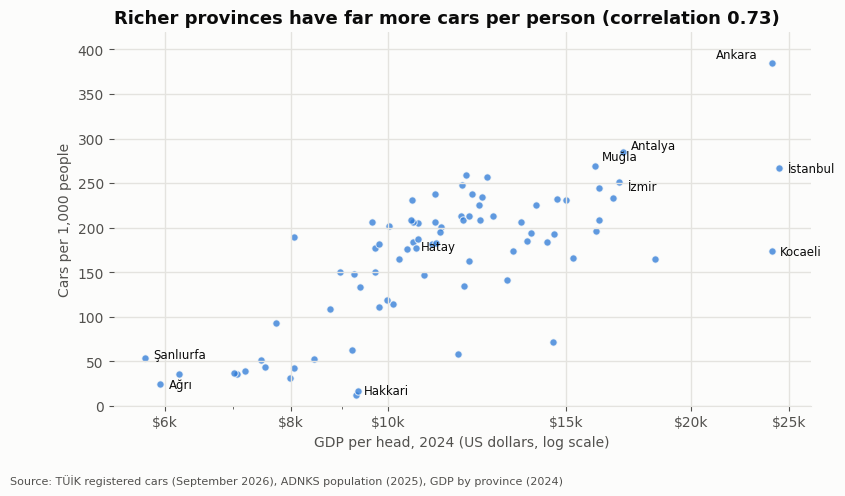

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.2))
scatter(ax, "cars_per_1000_people", {
    "Ankara": (-40, 4), "İstanbul": (6, -3), "Kocaeli": (6, -3), "Antalya": (6, 2), "İzmir": (6, -6),
    "Şanlıurfa": (6, 0), "Ağrı": (6, -3), "Hakkari": (6, 0), "Hatay": (6, -6), "Muğla": (5, 4),
})
r = correlations(provinces, "log_gdp", "cars_per_1000_people")
ax.set_title(f"Richer provinces have far more cars per person (correlation {r['pearson']:.2f})")
ax.set_ylabel("Cars per 1,000 people")
ax.set_ylim(0, 420)
plt.subplots_adjust(bottom=0.16)
add_source(fig, "Source: TÜİK registered cars (September 2026), ADNKS population (2025), GDP by province (2024)")
fig.savefig(FIGURES + "07_cars_vs_income.png", dpi=200)
plt.show()

In [6]:
cols = ["province", "gdp_per_capita_usd_2024", "hdi_2022", "cars_per_1000_people",
        "stations_per_100k_people", "stations_per_10k_cars"]
print("Richest 6 provinces")
display(provinces.nlargest(6, "gdp_per_capita_usd_2024")[cols].round(2))
print("Poorest 6 provinces")
display(provinces.nsmallest(6, "gdp_per_capita_usd_2024")[cols].round(2))

Richest 6 provinces


,province,gdp_per_capita_usd_2024,hdi_2022,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars
0,İstanbul,24451.61,0.89,267.25,17.41,6.51
19,Kocaeli,24031.32,0.89,174.06,13.93,8.00
22,Ankara,24030.91,0.89,384.26,21.78,5.67
3,Tekirdağ,18406.45,0.86,165.19,13.82,8.37
25,Antalya,17102.74,0.86,284.47,28.15,9.90
6,İzmir,16948.80,0.87,250.91,12.54,5.00


Poorest 6 provinces


,province,gdp_per_capita_usd_2024,hdi_2022,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars
76,Şanlıurfa,5731.42,0.75,53.52,3.31,6.18
60,Ağrı,5929.89,0.75,24.65,3.05,12.38
71,Van,6185.45,0.76,35.93,4.77,13.26
70,Muş,7015.59,0.77,36.69,5.40,14.71
68,Bitlis,7063.40,0.78,35.44,5.83,16.44
77,Batman,7202.10,0.81,39.17,5.43,13.87


**How to read this chart:** each dot is a province. Further right means higher GDP per head (log scale: each step is a similar percentage increase), higher up means more cars per 1,000 people.

**What it shows**
- **Car ownership rises steeply with income** (Pearson 0.73, Spearman 0.70; almost unchanged without Istanbul and Ankara). The poorest provinces in the south-east and east have 25–55 cars per 1,000 people (Ağrı 25, Şanlıurfa 54); the western and coastal provinces 200–290; Ankara 384.
- **Kocaeli is the clear exception:** as rich as Istanbul and Ankara by GDP ($24,000) but only 174 cars per 1,000 people, because its GDP comes from industry, not from household income.
- Antalya and Muğla have more cars than their income suggests, probably because of rental cars registered there for tourism.

**Why it matters:** electric cars are bought by car buyers. As long as car ownership follows income this closely, future charging demand will be concentrated in the western and coastal provinces and in the big cities. In the east, demand will grow mainly as car ownership itself grows.

## 3. Public charging and income

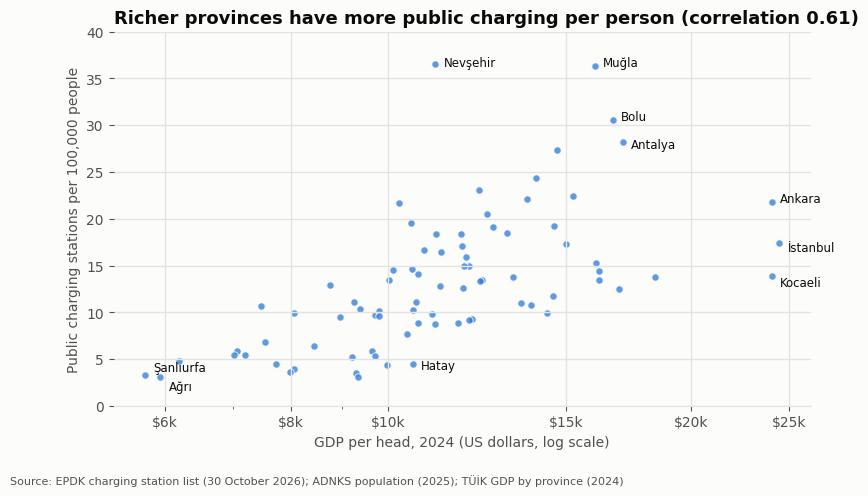

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
scatter(ax, "stations_per_100k_people", {
    "Nevşehir": (6, -2), "Muğla": (6, 0), "Bolu": (6, 0), "Antalya": (6, -4), "Ankara": (6, 0),
    "İstanbul": (6, -6), "Kocaeli": (6, -8), "Hatay": (6, -4), "Ağrı": (6, -9), "Şanlıurfa": (6, 3),
})
r = correlations(provinces, "log_gdp", "stations_per_100k_people")
ax.set_title(f"Richer provinces have more public charging per person (correlation {r['pearson']:.2f})")
ax.set_ylabel("Public charging stations per 100,000 people")
ax.set_ylim(0, 40)
plt.subplots_adjust(bottom=0.16)
add_source(fig, "Source: EPDK charging station list (30 October 2026); ADNKS population (2025); TÜİK GDP by province (2024)")
fig.savefig(FIGURES + "08_charging_vs_income.png", dpi=200)
plt.show()

In [8]:
# Provinces furthest above and below what their income would suggest (straight line on log income)
slope, intercept = np.polyfit(provinces["log_gdp"], provinces["stations_per_100k_people"], 1)
provinces["expected_per_100k"] = intercept + slope * provinces["log_gdp"]
provinces["above_expected"] = provinces["stations_per_100k_people"] - provinces["expected_per_100k"]
print("Most above the line")
display(provinces.nlargest(6, "above_expected")[cols + ["above_expected"]].round(1))
print("Most below the line")
display(provinces.nsmallest(6, "above_expected")[cols + ["above_expected"]].round(1))

Most above the line


,province,gdp_per_capita_usd_2024,hdi_2022,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars,above_expected
36,Nevşehir,11126.3,0.8,238.2,36.5,15.3,23.5
9,Muğla,16040.3,0.9,269.2,36.3,13.5,17.8
17,Bolu,16703.3,0.9,232.9,30.6,13.1,11.5
5,Çanakkale,14703.8,0.9,231.7,27.4,11.8,10.2
10,Afyonkarahisar,10243.3,0.8,164.7,21.7,13.2,9.9
25,Antalya,17102.7,0.9,284.5,28.2,9.9,8.7


Most below the line


,province,gdp_per_capita_usd_2024,hdi_2022,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars,above_expected
19,Kocaeli,24031.3,0.9,174.1,13.9,8.0,-10.6
30,Hatay,10569.9,0.8,184.1,4.5,2.4,-7.7
0,İstanbul,24451.6,0.9,267.2,17.4,6.5,-7.4
80,Şırnak,9326.2,0.8,16.7,3.1,18.8,-7.2
72,Adıyaman,9976.9,0.8,119.0,4.4,3.7,-7.0
23,Karaman,14373.9,0.8,184.3,9.9,5.4,-6.9


**How to read this chart:** the same income axis as above; higher up means more public charging stations per 100,000 people.

**What it shows**
- **Public charging per person follows income** (Pearson 0.61, Spearman 0.70). The poorest provinces have 3–6 stations per 100,000 people; most western provinces 12–20.
- **But per car, the link almost disappears** (Pearson −0.21, Spearman −0.12; table above). Richer provinces have more stations per person mainly because they have more cars per person. In other words, **the network has broadly gone where the cars are**, not specifically to rich places.
- **Above the line: tourism and main roads.** Nevşehir (Cappadocia), Muğla, Bolu (on the Istanbul–Ankara motorway), Çanakkale and Antalya have far more stations than their income suggests. These stations serve visitors and through traffic.
- **Below the line: Kocaeli, Hatay, Istanbul and Adıyaman.** Kocaeli's GDP overstates household income (see section 2). Hatay and Adıyaman are the earthquake provinces from notebook 04. **Istanbul** has 7 fewer stations per 100,000 people than its income suggests, and as the largest market it is the most important gap on this chart.

## 4. Five development groups

The 81 provinces are split into five groups of 16–17 provinces by HDI, from the least developed fifth (1) to the most developed fifth (5). For each group, three things are compared:
- **Car ownership:** cars per 1,000 people (future demand).
- **Charging per person:** public stations per 100,000 people.
- **Charging per car:** public stations per 10,000 cars (the measure from notebook 04).

Groups are calculated from totals (e.g. all stations in the group divided by all cars in the group), so large and small provinces count in proportion to their size.

In [9]:
provinces["hdi_group"] = pd.qcut(provinces["hdi_2022"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
groups = provinces.groupby("hdi_group").agg(
    provinces=("province", "size"),
    hdi_min=("hdi_2022", "min"), hdi_max=("hdi_2022", "max"),
    public_stations=("public_stations", "sum"), cars=("cars", "sum"), population=("population_2025", "sum"),
)
groups["cars_per_1000_people"] = groups["cars"] / groups["population"] * 1000
groups["stations_per_100k_people"] = groups["public_stations"] / groups["population"] * 100_000
groups["stations_per_10k_cars"] = groups["public_stations"] / groups["cars"] * 10_000
groups["population_share_%"] = groups["population"] / groups["population"].sum() * 100
groups.round(2)

,provinces,hdi_min,hdi_max,public_stations,cars,population,cars_per_1000_people,stations_per_100k_people,stations_per_10k_cars,population_share_%
hdi_group,,,,,,,,,,
1,17,0.75,0.81,758,788638,11969571,65.89,6.33,9.61,13.90
2,16,0.81,0.82,892,1667487,10321112,161.56,8.64,5.35,11.99
3,16,0.83,0.84,1870,2708462,13488199,200.80,13.86,6.90,15.67
4,16,0.84,0.85,1826,2285522,10632937,214.95,17.17,7.99,12.35
5,16,0.85,0.89,7390,10665766,39680349,268.79,18.62,6.93,46.09


In [10]:
for g in range(1, 6):
    print(g, ", ".join(provinces.loc[provinces["hdi_group"] == g, "province"]))

1 Yozgat, Tokat, Gümüşhane, Ordu, Ağrı, Iğdır, Kars, Bitlis, Muş, Van, Adıyaman, Diyarbakır, Şanlıurfa, Batman, Mardin, Siirt, Şırnak
2 Afyonkarahisar, Hatay, Kahramanmaraş, Osmaniye, Aksaray, Niğde, Bartın, Kastamonu, Sinop, Çorum, Giresun, Erzurum, Bingöl, Hakkari, Gaziantep, Kilis
3 Aydın, Kütahya, Manisa, Konya, Adana, Nevşehir, Sivas, Karabük, Amasya, Samsun, Rize, Trabzon, Bayburt, Ardahan, Elazığ, Malatya
4 Edirne, Balıkesir, Denizli, Uşak, Düzce, Sakarya, Karaman, Burdur, Isparta, Mersin, Kırıkkale, Kırşehir, Kayseri, Zonguldak, Çankırı, Erzincan
5 İstanbul, Kırklareli, Tekirdağ, Çanakkale, İzmir, Muğla, Bilecik, Bursa, Eskişehir, Bolu, Kocaeli, Yalova, Ankara, Antalya, Artvin, Tunceli


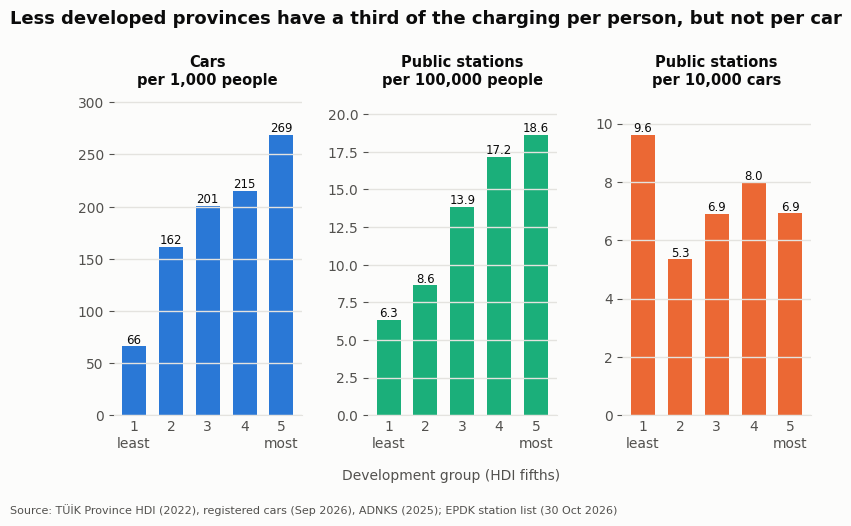

In [11]:
panels = [("cars_per_1000_people", "Cars\nper 1,000 people", BLUE, "{:.0f}"),
          ("stations_per_100k_people", "Public stations\nper 100,000 people", AQUA, "{:.1f}"),
          ("stations_per_10k_cars", "Public stations\nper 10,000 cars", ORANGE, "{:.1f}")]
fig, axes = plt.subplots(1, 3, figsize=(9, 5.2))
for ax, (col, title, color, fmt) in zip(axes, panels):
    ax.bar(groups.index, groups[col], color=color, width=0.65)
    for x, value in zip(groups.index, groups[col]):
        ax.text(x, value, fmt.format(value), ha="center", va="bottom", fontsize=8.5, color=TEXT)
    ax.set_title(title, fontsize=10.5, loc="center")
    ax.set_xticks(groups.index)
    ax.set_xticklabels(["1\nleast", "2", "3", "4", "5\nmost"])
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, groups[col].max() * 1.15)
fig.suptitle("Less developed provinces have a third of the charging per person, but not per car",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.supxlabel("Development group (HDI fifths)", fontsize=10, color=TEXT_2, y=0.07)
plt.subplots_adjust(top=0.82, bottom=0.2, wspace=0.35)
add_source(fig, "Source: TÜİK Province HDI (2022), registered cars (Sep 2026), ADNKS (2025); EPDK station list (30 Oct 2026)")
fig.savefig(FIGURES + "09_development_groups.png", dpi=200)
plt.show()

**How to read this chart:** three small charts with the same five groups on the horizontal axis, from the least developed fifth (left) to the most developed fifth (right).

**What it shows**
- **Left:** car ownership rises steadily with development, from 66 cars per 1,000 people in the least developed fifth to 269 in the most developed fifth (four times as many).
- **Middle:** public charging per person rises in the same way, from 6.3 to 18.6 stations per 100,000 people (three times as many).
- **Right:** per car, there is no clear pattern. The least developed fifth has the **most** stations per car (9.6), because it has so few cars, and the second fifth has the **least** (5.3). The second fifth includes most of the earthquake provinces from notebook 04 (Hatay, Kahramanmaraş, Osmaniye, Gaziantep and Kilis; Adıyaman is in the first).
- The most developed fifth holds **46% of Türkiye's population** and 59% of its cars.

**Interpretation:** like in the UK, today's public network has broadly followed demand. Less developed provinces have a third of the charging per person, but this is not a shortage today, because they have a quarter of the cars per person. It will become one as car ownership grows there. The clearer problem is in **group 2**, where car ownership is already substantial (162 cars per 1,000 people) but charging per car is the lowest of all groups.

In [12]:
provinces[["province_code", "hdi_group", "expected_per_100k", "above_expected"]].to_csv(
    PROCESSED + "province_development_groups.csv", index=False)
print(provinces["hdi_group"].value_counts().sort_index().to_dict())

{1: 17, 2: 16, 3: 16, 4: 16, 5: 16}


## Answer to question 3

- **Future demand follows income.** Car ownership rises steeply with income and development (correlation about 0.7): from about 66 cars per 1,000 people in the least developed fifth of provinces to 269 in the most developed fifth. Most future electric cars will be in the western and coastal provinces and the big cities.
- **Public charging per person also follows income**, with three times as many stations per person in the most developed fifth as in the least developed. **Per car, the link disappears:** the network has broadly gone where the cars are.
- **Poorer provinces are not short of charging today, but will be.** Their charging per person is low, but so is their car ownership. As car ownership grows, they will need more stations even before many people there buy electric cars.
- **The sharpest gaps are not the poorest provinces.** They are lower-middle development provinces (group 2) such as Hatay, Kahramanmaraş, Osmaniye and Gaziantep, and, relative to its income, **Istanbul**. Tourism and motorway provinces (Nevşehir, Muğla, Bolu) are well above what their income suggests.

Question 4 combines charging per car, car ownership, income and home parking into a priority list.